# RecoMart - Data Preparation and Exploratory Data Analysis
DSE ZG529 Experiential Learning Assignment · Member 2 (Akriti Adarsh)

This notebook runs the preparation stage on the raw data lake and explores the cleaned data: interaction distributions, item popularity, sparsity and ratings.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from recomart import preparation, eda
from recomart.plotting import style, INK, GREY, RUST, OCHRE, OLIVE
style(); pd.set_option('display.width', 140)

## 1. Cleaning and preprocessing
Duplicates are dropped, invalid rows are quarantined with a reason code, missing categoricals are imputed, categories are encoded and numeric columns normalised.

In [2]:
summary = preparation.prepare()
pd.DataFrame({k: v for k, v in summary.items() if k not in ('quarantine', 'interactions')}).T

,raw,clean,prices_fixed,duplicates_removed
products,600.0,600.0,2.0,NaN
users,1500.0,1500.0,NaN,NaN
events,116330.0,114282.0,NaN,1719.0
orders,9782.0,9600.0,NaN,NaN
ratings,3240.0,3025.0,NaN,NaN


In [3]:
pd.DataFrame(summary['quarantine']).fillna(0).astype(int)

,events,orders,ratings
unknown_product,224,0,0
invalid_timestamp,105,0,0
invalid_quantity,0,91,0
rating_out_of_range,0,0,81


In [4]:
P = '../data/processed/'
ev = pd.read_parquet(P + 'events.parquet'); prod = pd.read_parquet(P + 'products.parquet')
inter = pd.read_parquet(P + 'interactions.parquet'); rt = pd.read_parquet(P + 'ratings.parquet')
prod[['product_id','category','brand','price','price_minmax','log_price_z','brand_code','cat_Electronics','cat_Fashion']].head()

,product_id,category,brand,price,price_minmax,log_price_z,brand_code,cat_Electronics,cat_Fashion
0,P10001,Electronics,Zentek,1203.0,0.017306,-0.009199,32,1,0
1,P10002,Fashion,Strider,563.0,0.007700,-0.520863,26,0,1
2,P10003,Home,Nestwell,1760.0,0.025666,0.247347,17,0,0
3,P10004,Beauty,Rasa,344.0,0.004413,-0.852488,23,0,0
4,P10005,Sports,Stamina,16185.0,0.242180,1.744025,25,0,0


## 2. Interaction distribution

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
order = ['view','wishlist','add_to_cart','purchase']
ev['event_type'].value_counts().reindex(order).plot.bar(ax=ax[0], color=[GREY, OCHRE, OLIVE, RUST], rot=0)
ax[0].set_title('Events by type (funnel)')
per_user = inter.groupby('user_id')['n_events'].sum()
ax[1].hist(per_user, bins=50, color=INK); ax[1].set_yscale('log'); ax[1].set_title('Events per user (log)')
plt.show(); per_user.describe().round(1)

count    1422.0
mean       80.4
std        75.0
min         2.0
25%        31.0
50%        59.0
75%       106.0
max       621.0
Name: n_events, dtype: float64

## 3. Item popularity (long tail)

In [6]:
item_cnt = inter.groupby('product_id')['n_events'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.4)); ax.plot(range(1, len(item_cnt)+1), item_cnt.values, color=RUST)
ax.set_yscale('log'); ax.set_xlabel('item rank'); ax.set_ylabel('events'); ax.set_title('Item popularity')
plt.show()
print(f'Top 10% of items receive {item_cnt.iloc[:len(item_cnt)//10].sum()/item_cnt.sum():.1%} of interactions; '
      f'Gini = {eda.gini(item_cnt.values):.2f}')

Top 10% of items receive 48.1% of interactions; Gini = 0.63


## 4. Sparsity of the user-item matrix

In [7]:
n_u, n_i = inter.user_id.nunique(), inter.product_id.nunique()
print(f'{len(inter):,} observed user-item pairs out of {n_u*n_i:,} possible -> sparsity {1-len(inter)/(n_u*n_i):.2%}')
print(f'Purchased pairs only -> sparsity {1-inter.purchased.sum()/(n_u*n_i):.2%}')

49,606 observed user-item pairs out of 850,356 possible -> sparsity 94.17%
Purchased pairs only -> sparsity 99.00%


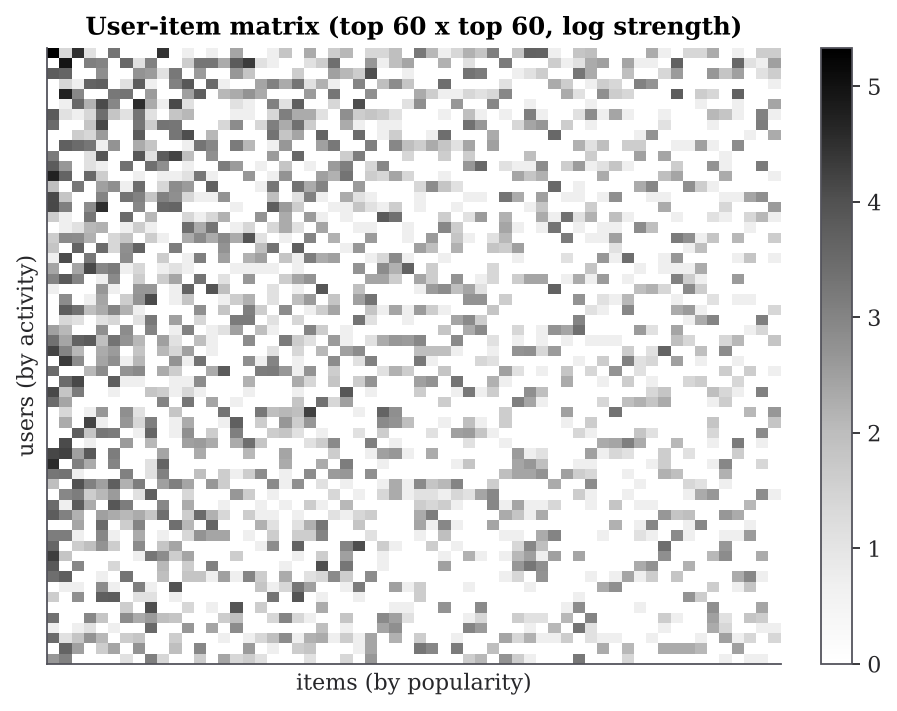

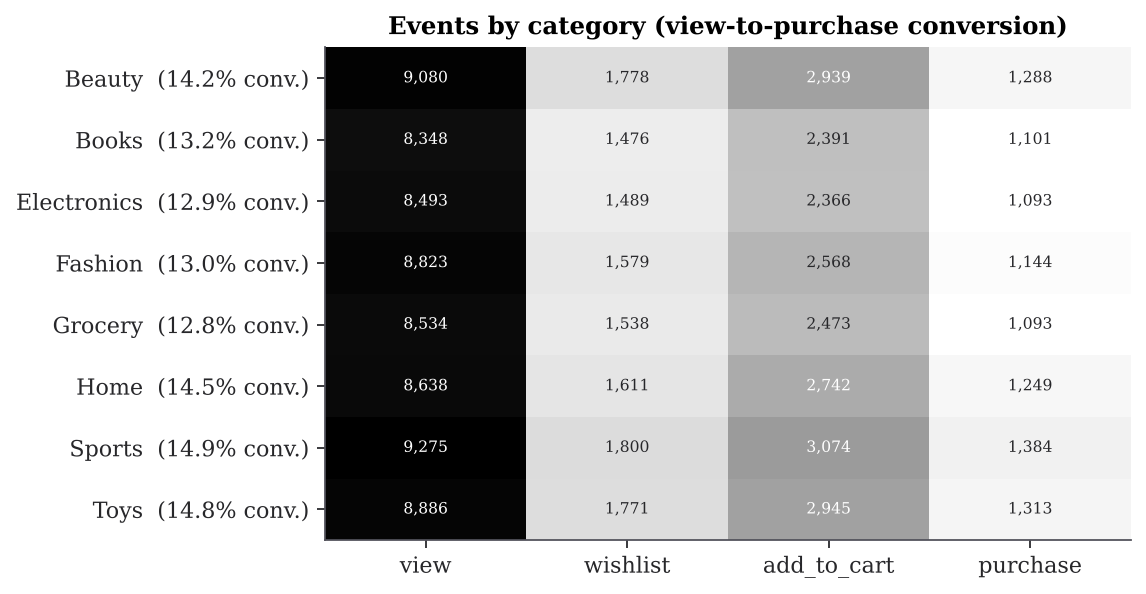

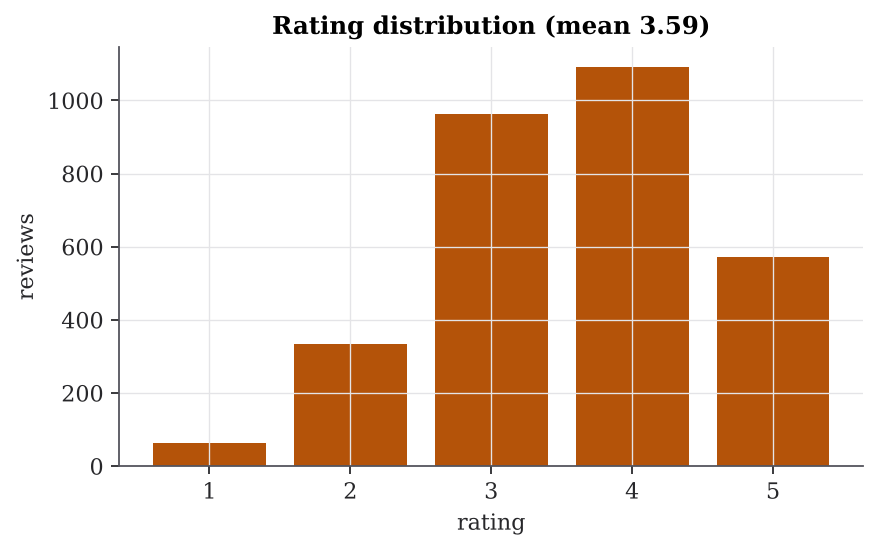

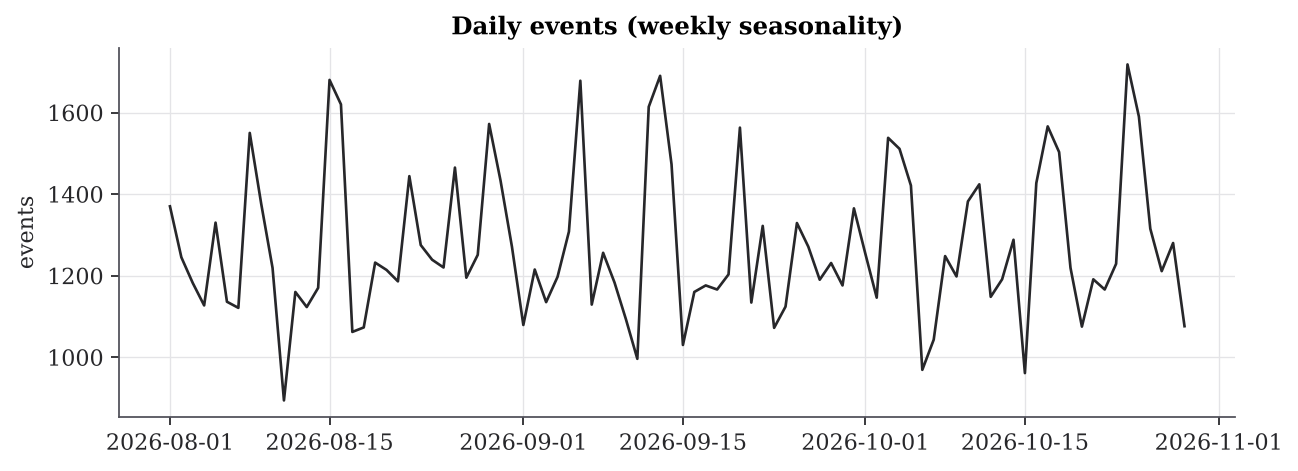

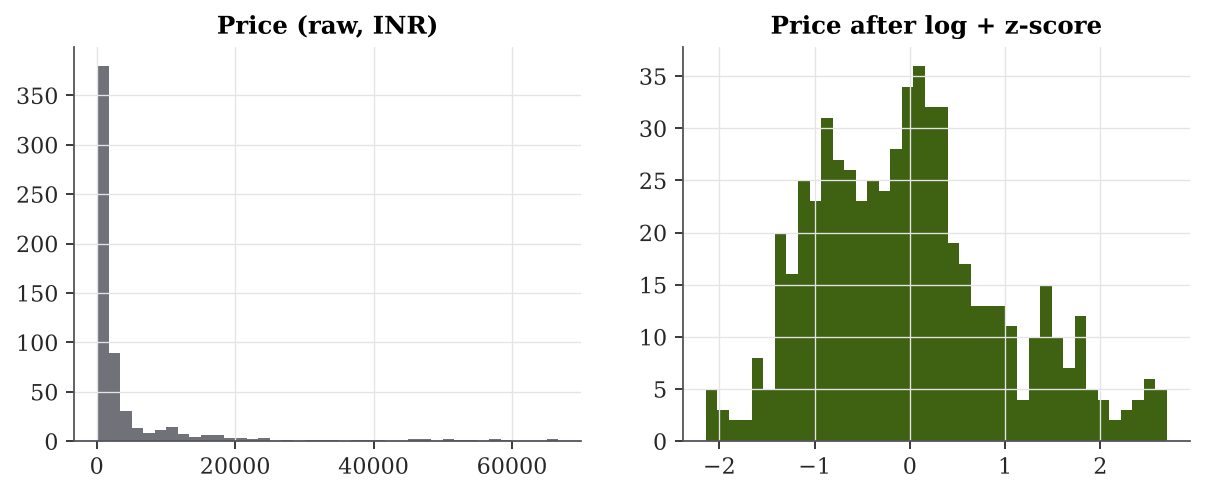

In [8]:
summary_eda = eda.run_eda()
from IPython.display import Image, display
for f in ['04_sparsity_heatmap', '06_category_event_heatmap', '05_rating_distribution', '07_daily_activity', '08_price_normalisation']:
    display(Image(filename=f'../reports/figures/{f}.png', width=640))

## 5. Findings
* The funnel is steep: roughly 1 purchase per 7 views, so purchases alone are too sparse to train on - views, wishlist and cart events are used as weighted implicit feedback.
* Activity and popularity are long-tailed: a small share of items gets most interactions, so a popularity baseline is strong and personalised models must beat it.
* The purchase matrix is about 99% empty, which motivates matrix factorisation and co-occurrence features.
* Ratings are skewed towards 4-5, so the Bayesian-smoothed rating is used as an item feature.

In [9]:
{k: v for k, v in summary_eda.items() if k != 'figures'}

{'events': 114282,
 'users_active': 1422,
 'items_interacted': 598,
 'user_item_pairs': 49606,
 'sparsity_pct': 94.17,
 'purchase_pairs_sparsity_pct': np.float64(99.0),
 'item_popularity_gini': 0.634,
 'top10pct_items_share': 0.481,
 'median_events_per_user': 59.0,
 'mean_rating': 3.59,
 'view_to_purchase_pct': np.float64(13.79)}